# E- handelsanalyysis

## Project syfte

Analysera försäljningsdata for att idetentifera använbara mönster och ge ledgning beslut innan nästa kampanjperiod.

## Frågeställningar

1. Vilka produkt kategorier driver mest intäkt?
2. Vilka städer står för störst intäkt?
3. Hur ser ut Försaljningen över tid?
4. Hur ser en typisk order ut? – AOV (Average Order Value) och spridning.
5. Topp-listor – topp-3 kategorier efter intäkt.
6. Finns det avvikelser eller något oväntat mönster i data?



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys
sys.path.append("..")

In [2]:
import os

project_root = os.path.abspath("..")
print(project_root)
print(os.listdir(project_root))

d:\users\emma\OneDrive\Dokument\01. Kurser\01. Data Science\02. Pythonprogrammering och statistisk dataanalys\Gruppuppgift\Gruppuppgift VScode\E_Handel_Analysis_Group5
['.git', '.gitignore', '.venv', 'data', 'notebooks', 'README.md', 'requirements.txt', 'src']


In [3]:
import sys
sys.path.append("..")

from src.io_utils import load_data

df = pd.read_csv("../data/ecommerce_sales.csv")

print("Data loaded")


Data loaded


In [4]:
df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


In [5]:
print("Ecommerce data Information")
df.info()


Ecommerce data Information
<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   int64  
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2500 non-null   int64  
 6   revenue   2500 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 136.8 KB


In [6]:
print("Statistics")

print(df.describe())
print()

Statistics
           order_id        price        units      revenue
count    2500.00000  2500.000000  2500.000000  2500.000000
mean   101249.50000   476.213212     2.985200  1401.106892
std       721.83216   312.968413     1.429755  1166.944967
min    100000.00000    50.000000     1.000000    50.000000
25%    100624.75000   254.960000     2.000000   577.960000
50%    101249.50000   413.045000     3.000000  1088.690000
75%    101874.25000   624.427500     4.000000  1884.750000
max    102499.00000  2092.530000     9.000000  9192.600000



In [7]:

df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Date:" "From", df["date"] . min() , "to" ,df["date"].max())

Date:From 2024-01-01 00:00:00 to 2024-06-30 00:00:00


In [8]:
print("Cities:" ,list(df["city"].unique()))
print()

print("Produkt Categories:" ,list(df["category"].unique()))
print()

Cities: ['Stockholm', 'Malmö', 'Uppsala', 'Göteborg', 'Västerås']

Produkt Categories: ['Sports', 'Clothing', 'Home', 'Electronics', 'Toys', 'Beauty']



## Beräkna total Intäkten

In [9]:
#Total intäkt och Antal enheter

total_intäkt = df["revenue"].sum()
print(f"Total intäkt: {total_intäkt:,.2f} kr")
print()

antal_enheter = df["units"].sum()
print(f"Total antal enheter: {antal_enheter}")


Total intäkt: 3,502,767.23 kr

Total antal enheter: 7463


## Intäkt per stad

In [10]:
#Intäkt Per Stad

#Tabell
import importlib
import src.metrics as metrics

stads_intäkt = metrics.intäkt_per_stad(df)

stads_intäkt_tabell = stads_intäkt.reset_index()
stads_intäkt_tabell.columns = ["Stad" , "Total intäkt"]

display(stads_intäkt_tabell)



,Stad,Total intäkt
0,Stockholm,1227201.94
1,Göteborg,859019.65
2,Malmö,567926.32
3,Uppsala,551478.42
4,Västerås,297140.90


In [11]:
högst_intäkt_stad = stads_intäkt.idxmax()
hogsta_stads_intakt = stads_intäkt.max()

print(f"Stad med högst intäkt: {högst_intäkt_stad}")
print(f"Högsta stads intäkten: {hogsta_stads_intakt:,.2f} kr")

Stad med högst intäkt: Stockholm
Högsta stads intäkten: 1,227,201.94 kr


In [12]:
# kategori intäkt 

In [13]:
# Top tre kategori

In [14]:
# månads intäkt

In [15]:
#aov

In [16]:
#ordervalue distribution


import importlib
import src.metrics as metrics

importlib.reload(metrics)

order_values = metrics.ordervarden(df)

print("Antal unika orderr:", order_values.size)
print(f"Lägsta ordervärde: {order_values.min():,.2f} kr")
print(f"Median för ordervärde: {order_values.median():,.2f} kr")
print(f"Högsta ordervärde: {order_values.max():,.2f} kr")

Antal unika orderr: 2500
Lägsta ordervärde: 50.00 kr
Median för ordervärde: 1,088.69 kr
Högsta ordervärde: 9,192.60 kr


In [17]:
nyckeltal_tabell = pd.DataFrame({
    "Nyckeltal": [
        "Total intäkt",
        "Totalt antal sålda enheter",
        "Antal unika ordrar",
        "Stad med högst intäkt",
    ],
    "Resultat": [
        f"{total_intäkt:,.2f} kr",
        f"{antal_enheter:,}",
        f"{order_values.size:,}",
        str(stads_intäkt.idxmax()),
        
    ]
})

display(nyckeltal_tabell)


,Nyckeltal,Resultat
0,Total intäkt,"3,502,767.23 kr"
1,Totalt antal sålda enheter,"7,463"
2,Antal unika ordrar,"2,500"
3,Stad med högst intäkt,Stockholm


# Visualization

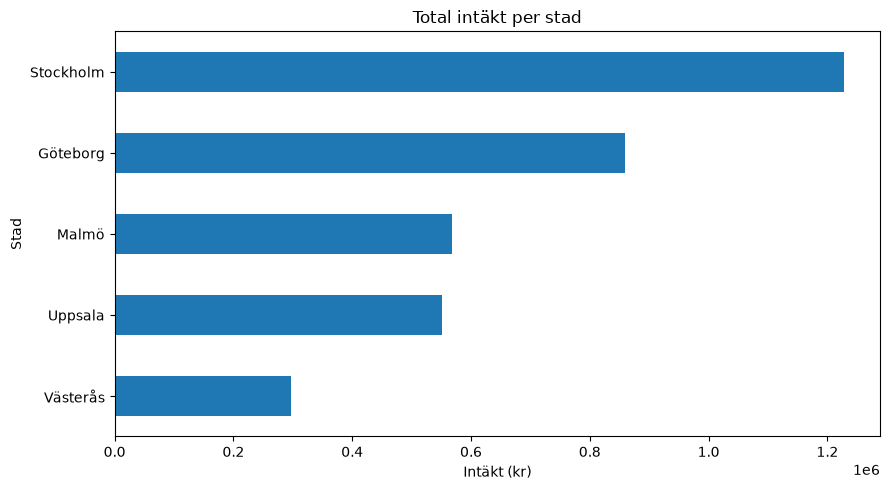

In [18]:
#plot intäkt per stad

import importlib
import src.viz as viz

importlib.reload(viz)

viz.plot_intakt_per_stad(stads_intäkt)

In [19]:
#plot kategory

In [20]:
#plot topp tre kategori

In [21]:
#plot försäjlning over tid

In [22]:
#Aov

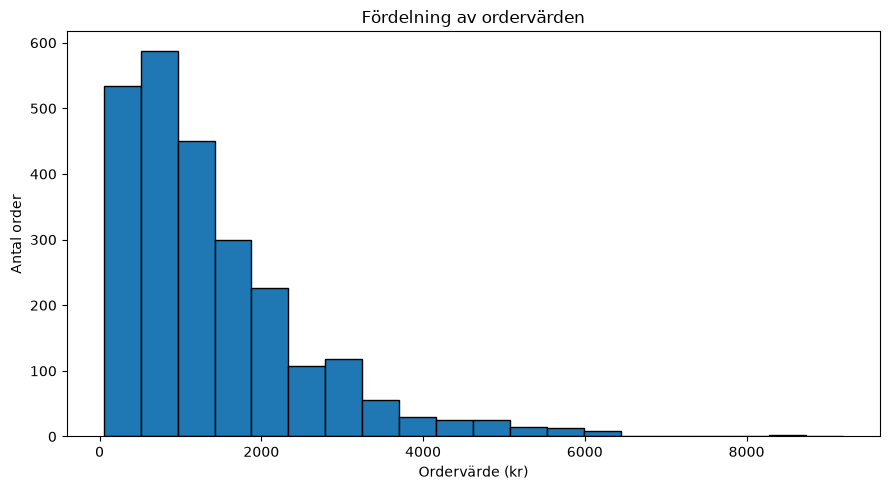

In [23]:
#order value distributin


import importlib
import src.viz as viz

importlib.reload(viz)

viz.plot_ordervarden(order_values)

## Analysera  avvikelser och något oväntat mönster


In [24]:
# Saknande värden per kolumn
print(df.isnull().sum())

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Invalid or unusual values
print("Price <= 0:", (df["price"] <= 0).sum())
print("Units <= 0:", (df["units"] <= 0).sum())
print("Revenue < 0:", (df["revenue"] < 0).sum())

order_id    0
date        0
city        0
category    0
price       0
units       0
revenue     0
dtype: int64
Duplicate rows: 0
Price <= 0: 0
Units <= 0: 0
Revenue < 0: 0


In [25]:

import numpy as np
import pandas as pd

kolumner = ["price", "units", "revenue"]

sammanfattningar = []
outlier_limit = {}
outlier_data = {}

for kolumn in kolumner:
    values = df[kolumn].dropna().to_numpy()

    minimum = np.min(values)
    q1 = np.percentile(values, 25)
    median = np.median(values)
    q3 = np.percentile(values, 75)
    maximum = np.max(values)

    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    # Identifiera potentiella avvikande värden
    mask = (df[kolumn] < lower_limit) | (
        df[kolumn] > upper_limit
    )
    avvikelser = df.loc[mask]

    sammanfattningar.append({
        "Kolumn": kolumn,
        "Minimum": minimum,
        "Q1": q1,
        "Median": median,
        "Q3": q3,
        "Maximum": maximum,
        "IQR": iqr,
        "Antal avvikelser": len(avvikelser)
    })

    outlier_limit[kolumn] = (
        lower_limit, upper_limit
    )
    outlier_data[kolumn] = avvikelser

sammanfattning = pd.DataFrame(sammanfattningar)

display(sammanfattning.round(2))


,Kolumn,Minimum,Q1,Median,Q3,Maximum,IQR,Antal avvikelser
0,price,50.0,254.96,413.04,624.43,2092.53,369.47,88
1,units,1.0,2.00,3.00,4.00,9.00,2.00,7
2,revenue,50.0,577.96,1088.69,1884.75,9192.60,1306.79,111


In [26]:
alla_avvikelser = pd.concat(
    [outlier_data[kolumn] for kolumn in kolumner]
).drop_duplicates()

print(f"Totalt antal unika rader med avvikelser: {len(alla_avvikelser)}")

display(
    alla_avvikelser[
        ["order_id", "date", "city",
         "category", "price", "units", "revenue"]
    ].sort_values("revenue", ascending=False)
)


Totalt antal unika rader med avvikelser: 162


,order_id,date,city,category,price,units,revenue
1411,101411,2024-02-26,Stockholm,Electronics,1838.52,5,9192.60
1339,101339,2024-02-26,Göteborg,Electronics,1703.37,5,8516.85
1491,101491,2024-06-04,Västerås,Electronics,2092.53,4,8370.12
1733,101733,2024-06-05,Uppsala,Electronics,1227.73,6,7366.38
1518,101518,2024-01-12,Göteborg,Electronics,1403.69,5,7018.45
...,...,...,...,...,...,...,...
1533,101533,2024-05-10,Västerås,Electronics,1264.50,1,1264.50
223,100223,2024-04-09,Malmö,Electronics,1257.95,1,1257.95
1408,101408,2024-04-20,Uppsala,Electronics,1236.04,1,1236.04
1722,101722,2024-06-27,Stockholm,Electronics,1222.72,1,1222.72


Datasetet innehåller 2 500 rader och 7 kolumner. Vi hittade inga saknade värden eller dubblettrader. Det fanns inte heller några negativa värden i kolumnerna price, units eller revenue.

Vi använde femtals-sammanfattningen och IQR-metoden för att identifiera potentiellt avvikande värden. Analysen visade 88 avvikande värden i price, 7 i units och 111 i revenue.

Resultaten visar att kategorin Electronics har flest avvikande värden, både för pris och intäkt. Detta kan bero på att elektronikprodukter ofta har högre priser och att försäljning av flera enheter kan ge högre intäkter.

# Fråga 4

In [27]:
import sys
sys.path.append("..")

import pandas as pd
from src.metrics import compute_aov, order_value_spread
from src.viz import plot_order_value_distribution

df = pd.read_csv("../data/ecommerce_sales.csv", parse_dates=["date"])
df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


df är en variabel, gör om csv-filen till en DataFrame som är pandas ord för en tabell med rader och kolumner

In [28]:
print("AOV:", round(compute_aov(df), 2), "kr")
order_value_spread(df)

AOV: 1401.11 kr


AOV (medel)    1401.11
Median         1088.69
Std            1166.94
Min              50.00
25 %            577.96
75 %           1884.75
Max            9192.60
dtype: float64

In [29]:
exempel = pd.Series([500, 600, 700, 800, 5000])

print("Medel:", exempel.mean())
print("Median:", exempel.median())

Medel: 1520.0
Median: 700.0


In [30]:
aov = compute_aov(df)
median = df["revenue"].median()
skillnad = aov - median
andel_under = (df["revenue"] < aov).mean() * 100
storsta = df["revenue"].max()

print("AOV (medel):", round(aov), "kr")
print("Median:", round(median), "kr")
print("Skillnad:", round(skillnad), "kr")
print("Andel ordrar under AOV:", round(andel_under, 1), "%")
print("Största order:", round(storsta), "kr")

AOV (medel): 1401 kr
Median: 1089 kr
Skillnad: 312 kr
Andel ordrar under AOV: 62.3 %
Största order: 9193 kr


Ovan, om medel och median vore lika skulle ungefär 50% ligga under. Här ligger 62% under, alltså är de flesta ordrar mindre än medelsnittet.

Medianen (cirka 1 090 kr) är lägre än AOV (cirka 1 400 kr) eftersom ett fåtal stora
ordrar, upp till över 9 000 kr, drar upp medelvärdet. Cirka 62 % av ordrarna ligger
under AOV. En typisk order ligger därför närmare medianen, men de stora ordrarna
bidrar mycket till den totala intäkten.

Hur ser en typisk order ut? – AOV (Average Order Value) och spridning.

SVAR: En typisk order ligger på cirka 1090kr (median). AOV, det genomsnittliga ordervärdet, är cirka 1400kr. AOV är högre än medianen pga fåtal stora ordrar som ligger på upp till 9190kr, det drar upp medelvärdet. Men cirka 62% av ordrarna ligger under AOV.

# Avvikelser
potentiella avvikelser jag fann under arbetets gång.

In [31]:
df.sort_values("revenue").tail(10)

,order_id,date,city,category,price,units,revenue
2282,102282,2024-06-25,Malmö,Sports,1048.89,6,6293.34
45,100045,2024-06-17,Västerås,Sports,1052.08,6,6312.48
116,100116,2024-02-10,Uppsala,Electronics,1593.28,4,6373.12
1601,101601,2024-04-15,Uppsala,Electronics,1287.06,5,6435.30
2191,102191,2024-01-02,Stockholm,Electronics,1103.14,6,6618.84
1518,101518,2024-01-12,Göteborg,Electronics,1403.69,5,7018.45
1733,101733,2024-06-05,Uppsala,Electronics,1227.73,6,7366.38
1491,101491,2024-06-04,Västerås,Electronics,2092.53,4,8370.12
1339,101339,2024-02-26,Göteborg,Electronics,1703.37,5,8516.85
1411,101411,2024-02-26,Stockholm,Electronics,1838.52,5,9192.60


In [32]:
df.sort_values("revenue").head(10)

,order_id,date,city,category,price,units,revenue
980,100980,2024-02-13,Malmö,Toys,50.00,1,50.00
1816,101816,2024-06-09,Stockholm,Home,50.00,1,50.00
1392,101392,2024-04-18,Stockholm,Electronics,50.00,1,50.00
1785,101785,2024-03-10,Stockholm,Home,50.00,1,50.00
1126,101126,2024-03-06,Uppsala,Electronics,50.00,1,50.00
1842,101842,2024-03-19,Stockholm,Toys,50.00,1,50.00
139,100139,2024-03-04,Malmö,Electronics,50.00,1,50.00
548,100548,2024-06-30,Göteborg,Home,50.00,1,50.00
2423,102423,2024-06-16,Malmö,Electronics,50.00,1,50.00
2001,102001,2024-03-03,Stockholm,Toys,51.14,1,51.14


.head() - huvud, början, visar de första raderna
.tail() - svans, slutet, visar de sista raderna

### Avvikelse 1
Stora ordrar
De flesta är Electronics, som har högst priser. Dessa ordrar drar upp AOV, och visar varför 62 % av ordrarna ligger under AOV.

In [33]:
q1 = df["revenue"].quantile(0.25)
q3 = df["revenue"].quantile(0.75)
grans = q3 + 1.5 * (q3 - q1)

stora = df[df["revenue"] > grans]

print("Gräns:", round(grans), "kr")
print("Antal stora ordrar:", len(stora))
stora["category"].value_counts()

Gräns: 3845 kr
Antal stora ordrar: 111


category
Electronics    92
Sports         16
Clothing        2
Home            1
Name: count, dtype: int64

## Avvikelse 2
Pris exakt 50 kr. Att så många har exakt samma lägsta pris kan tyda på ett fel i datan
och bör undersökas.

In [34]:
femtio = df[df["price"] == 50]

print("Antal ordrar med pris 50 kr:", len(femtio))
femtio["category"].value_counts()

Antal ordrar med pris 50 kr: 74


category
Toys           18
Electronics    17
Home           16
Clothing       10
Beauty          7
Sports          6
Name: count, dtype: int64

### Källor, fråga 4

Inläsning (första kodcellen)
- read_csv: https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
- sys.path: https://docs.python.org/3/library/sys.html#sys.path

Beräkningar (src/metrics.py: compute_aov och order_value_spread)
- sum: https://pandas.pydata.org/docs/reference/api/pandas.Series.sum.html
- nunique: https://pandas.pydata.org/docs/reference/api/pandas.Series.nunique.html
- mean: https://pandas.pydata.org/docs/reference/api/pandas.Series.mean.html
- median: https://pandas.pydata.org/docs/reference/api/pandas.Series.median.html
- std: https://pandas.pydata.org/docs/reference/api/pandas.Series.std.html
- min: https://pandas.pydata.org/docs/reference/api/pandas.Series.min.html
- max: https://pandas.pydata.org/docs/reference/api/pandas.Series.max.html
- quantile: https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html
- value_counts: https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html
- regeln för extremvärden: https://statisticsbyjim.com/basics/outliers/
- räkna ut Q1 & Q3: https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html
- Boolean indexing: https://pandas.pydata.org/docs/user_guide/indexing.html#boolean-indexing
- avrunda till heltal: https://docs.python.org/3/builtins/functions.html#round
- räkna antal rader: https://docs.python.org/3/builtins/functions.html#len
- räkna antal per kategorier: https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html


Histogram (src/viz.py: plot_order_value_distribution)
- figur: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html
- staplar: https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.hist.html
           https://seaborn.pydata.org/tutorial/distributions.html
- linjer för medel och median: https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.axvline.html
- förklaringsruta: https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.legend.html

mer
- round: https://docs.python.org/3/library/functions.html#round
- Markdown: https://www.markdownguide.org/basic-syntax/
- Markdown i Jupyter: https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html
- sorta: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html
         https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.tail.html

AOV medelvärder = alla ordervärden ihopräknade, delat med antalet ordrar.
Medianen = ordern i mitten, alla ordrar på rad från minst till störst. Hälften av ordrarna är mindre och hälften större.

## Varför skiljer sig medianen från AOV?
AOV är medelvärdet: all intäkt delat med antal ordrar.
Medianen är ordern i mitten när alla ordrar sorteras från minst till störst.
Om några få ordrar är mycket stora drar de upp medelvärdet, men inte medianen.

Om någon annan vill räkna AOV skriver de compute_aov(df) i stället för att kopiera kod.

# Fråga 5 - Vilka tre produktkategorier har högst total intäkt?

### Syfte


 Syftet med denna analys är att ta redapå vilka tre produktkategorier som har högst total intäkt. Jag använder försäljningsdata och jämför intäkterna mellan olika kategorier

### Metod


Jag använder Python och biblioteket Pandas för att analysera försäljningsdata. Jag grupperar produkterna efter kategori med (groupby) och räknar ihop intäkterna med (sum). Sedan använder jag (nlargest 3) för att hitta de tre kategorier som har högst total intäkt.

### Kod

In [17]:
top3 = df.groupby("category")["revenue"].sum().nlargest(3)
print(top3)

category
Electronics    1364228.07
Sports          734653.42
Clothing        586744.91
Name: revenue, dtype: float64


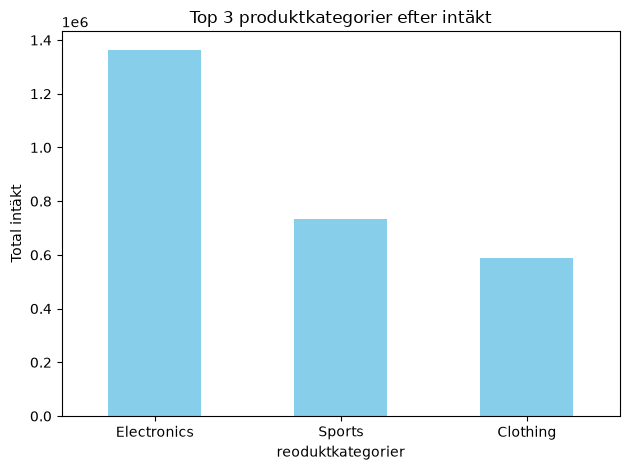

In [18]:
import matplotlib.pyplot as plt

top3.plot(kind="bar", color="skyblue")
plt.title("Top 3 produktkategorier efter intäkt")
plt.xlabel("reoduktkategorier")
plt.ylabel("Total intäkt")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Resultat


Resultaten visar att Electronics har högst total intäkt mes 1,364,228.07 På andra plats kommer Sport med 734,653.42 och på trdje plats Clothing med 586,744.91

Electronics har alltså mycket högre intäkt än de andra två katrgorierna.

### Slutsats

Min analys visar att Electronics är den katagori som ger högst total intäkt. Sports och Clothing kommer på andra och trrdje plats.

Jag tyker att företaget kan fortsätta satsa på Electronics eftersom den kategorin ger mest intäkter. Samtidigt kan företaget försöka öka försäljningen inom Sports och Clothing.

### Rekommendationer 

Utifrån min analys rekommenderar jag att företaget:
1. Fortsätter att satsa på Electronics eftersom kategorin har högst total intäkt.

2. Undersöker hur försäljningen inom Sports och Clothing kan öka, till exempel genom kampanjer.

3. Jämför antal sålda orodukter ovh vinst för att förstå vilka kategorier som är mest lönsamma.

4. Företaget kan undersöka vilka produkter kunderna köper mest och om vissa kategorier säljer bättre unser olika perioder.

5. Företaget bör jämföra intäkter med kostnader innan de bestämmer vilka produktkategorier de ska investera mer i.

### Reflektion


I den här uppgiften har jag lärt mig hur använder Python och Pandas för att jämföra intäkter mellan olika produktkategorier.

Jag använder groupby och sum för att räkna ut den totala intäkten och nlargest 3 för att hitta de tre största kategorierna.

En sak som är viktigt att tänka på är att hög vinst. För att få en bättre undersöka kostnader och antal sålda produkter.

### Källor

- Pandas – DataFrame.groupby():
  https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html

- Pandas – Series.nlargest():
  https://pandas.pydata.org/docs/reference/api/pandas.Series.nlargest.html

- Matplotlib – Pyplot:
  https://matplotlib.org/stable/api/pyplot_summary.html